In [1]:
import cv2
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

from google.colab import drive
from google.colab import files

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Lokasi folder dataset
folder_dataset = '/content/drive/MyDrive/dataset'

# Lokasi folder output
folder_output = '/content/drive/MyDrive/output_transformasi'

# Membuat folder output jika belum tersedia
os.makedirs(folder_output, exist_ok=True)

# Membaca semua file gambar
ekstensi = ('*.jpg', '*.jpeg', '*.png', '*.bmp')

daftar_gambar = []

for ext in ekstensi:
    daftar_gambar.extend(
        glob.glob(os.path.join(folder_dataset, ext))
    )

# Mengurutkan nama gambar
daftar_gambar = sorted(daftar_gambar)

# Memastikan minimal 20 gambar tersedia
if len(daftar_gambar) < 20:
    raise ValueError(
        f"Dataset hanya memiliki {len(daftar_gambar)} gambar. "
        "Minimal harus tersedia 20 gambar."
    )

# Mengambil 20 gambar pertama
daftar_gambar = daftar_gambar[:20]

print("Jumlah citra yang digunakan:", len(daftar_gambar))

for i, path in enumerate(daftar_gambar, 1):
    print(f"{i}. {os.path.basename(path)}")

Jumlah citra yang digunakan: 20
1. gambar01.jpg
2. gambar02.jpg
3. gambar03.jpg
4. gambar04.jpg
5. gambar05.jpg
6. gambar06.jpg
7. gambar07.jpg
8. gambar08.jpg
9. gambar09.jpg
10. gambar10.jpg
11. gambar11.jpg
12. gambar12.jpg
13. gambar13.jpg
14. gambar14.jpg
15. gambar15.jpg
16. gambar16.jpg
17. gambar17.jpg
18. gambar18.jpg
19. gambar19.jpg
20. gambar20.jpg


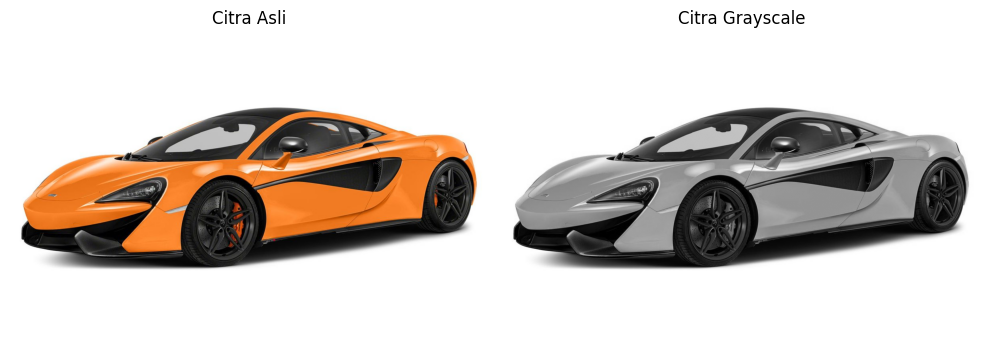

In [4]:
def baca_citra_grayscale(path):
    """
    Membaca citra dan mengubahnya menjadi grayscale.
    """

    # Membaca gambar
    img = cv2.imread(path)

    if img is None:
        raise ValueError(f"Gambar tidak dapat dibaca: {path}")

    # Konversi menjadi grayscale
    grayscale = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2GRAY
    )

    return grayscale


# Menguji pembacaan citra pertama
img_gray = baca_citra_grayscale(daftar_gambar[0])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
img_asli = cv2.imread(daftar_gambar[0])
plt.imshow(cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB))
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap='gray')
plt.title("Citra Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
def translasi(img, tx=50, ty=30):
    """
    Melakukan translasi pada citra.

    tx = pergeseran horizontal
    ty = pergeseran vertikal
    """

    tinggi, lebar = img.shape

    matriks = np.float32([
        [1, 0, tx],
        [0, 1, ty]
    ])

    hasil = cv2.warpAffine(
        img,
        matriks,
        (lebar, tinggi)
    )

    return hasil

In [6]:
def rotasi(img, sudut=45):
    """
    Melakukan rotasi pada citra.
    """

    tinggi, lebar = img.shape

    pusat = (lebar // 2, tinggi // 2)

    matriks = cv2.getRotationMatrix2D(
        pusat,
        sudut,
        1.0
    )

    hasil = cv2.warpAffine(
        img,
        matriks,
        (lebar, tinggi)
    )

    return hasil

In [7]:
def scaling(img, skala=1.5):
    """
    Melakukan scaling pada citra.
    """

    tinggi, lebar = img.shape

    ukuran_baru = (
        int(lebar * skala),
        int(tinggi * skala)
    )

    if skala > 1:
        interpolasi = cv2.INTER_LINEAR
    else:
        interpolasi = cv2.INTER_AREA

    hasil = cv2.resize(
        img,
        ukuran_baru,
        interpolation=interpolasi
    )

    return hasil

In [8]:
def shearing(img, shx=0.3, shy=0.0):
    """
    Melakukan shearing pada citra.
    """

    tinggi, lebar = img.shape

    matriks = np.float32([
        [1, shx, 0],
        [shy, 1, 0]
    ])

    hasil = cv2.warpAffine(
        img,
        matriks,
        (lebar, tinggi)
    )

    return hasil

In [9]:
def refleksi(img, arah=1):
    """
    Melakukan refleksi pada citra.

    arah = 1  : horizontal
    arah = 0  : vertikal
    arah = -1 : horizontal dan vertikal
    """

    hasil = cv2.flip(img, arah)

    return hasil

In [10]:
def transformasi_affine(img):
    """
    Melakukan transformasi affine pada citra.
    """

    tinggi, lebar = img.shape

    # Tiga titik pada citra asli
    titik_asal = np.float32([
        [0, 0],
        [lebar - 1, 0],
        [0, tinggi - 1]
    ])

    # Tiga titik tujuan
    titik_tujuan = np.float32([
        [lebar * 0.1, tinggi * 0.2],
        [lebar * 0.9, tinggi * 0.1],
        [lebar * 0.2, tinggi * 0.9]
    ])

    # Membentuk matriks affine
    matriks = cv2.getAffineTransform(
        titik_asal,
        titik_tujuan
    )

    # Menerapkan transformasi
    hasil = cv2.warpAffine(
        img,
        matriks,
        (lebar, tinggi)
    )

    return hasil

In [11]:
def transformasi_perspektif(img):
    """
    Melakukan transformasi perspektif pada citra.
    """

    tinggi, lebar = img.shape

    # Empat titik pada citra asli
    titik_asal = np.float32([
        [0, 0],
        [lebar - 1, 0],
        [0, tinggi - 1],
        [lebar - 1, tinggi - 1]
    ])

    # Empat titik tujuan
    titik_tujuan = np.float32([
        [lebar * 0.1, tinggi * 0.1],
        [lebar * 0.9, tinggi * 0.0],
        [lebar * 0.2, tinggi * 0.9],
        [lebar * 0.8, tinggi * 0.8]
    ])

    # Membentuk matriks perspektif
    matriks = cv2.getPerspectiveTransform(
        titik_asal,
        titik_tujuan
    )

    # Menerapkan transformasi perspektif
    hasil = cv2.warpPerspective(
        img,
        matriks,
        (lebar, tinggi)
    )

    return hasil

In [12]:
def proses_semua_transformasi(img):
    """
    Menjalankan seluruh transformasi geometris
    pada satu citra grayscale.
    """

    hasil = {
        "translasi": translasi(img, tx=50, ty=30),

        "rotasi": rotasi(img, sudut=45),

        "scaling": scaling(img, skala=1.5),

        "shearing": shearing(img, shx=0.3, shy=0.0),

        "refleksi": refleksi(img, arah=1),

        "affine": transformasi_affine(img),

        "perspektif": transformasi_perspektif(img)
    }

    return hasil

In [13]:
# Membuat folder untuk setiap transformasi
jenis_transformasi = [
    "grayscale",
    "translasi",
    "rotasi",
    "scaling",
    "shearing",
    "refleksi",
    "affine",
    "perspektif"
]

for jenis in jenis_transformasi:
    os.makedirs(
        os.path.join(folder_output, jenis),
        exist_ok=True
    )


# Memproses seluruh citra
for i, path in enumerate(daftar_gambar, 1):

    # Membaca dan mengubah citra menjadi grayscale
    img = baca_citra_grayscale(path)

    # Mengambil nama file
    nama_file = os.path.splitext(
        os.path.basename(path)
    )[0]

    # Menyimpan citra grayscale
    cv2.imwrite(
        os.path.join(
            folder_output,
            "grayscale",
            nama_file + "_grayscale.jpg"
        ),
        img
    )

    # Melakukan seluruh transformasi
    hasil = proses_semua_transformasi(img)

    # Menyimpan setiap hasil transformasi
    for jenis, citra_hasil in hasil.items():

        path_simpan = os.path.join(
            folder_output,
            jenis,
            nama_file + "_" + jenis + ".jpg"
        )

        cv2.imwrite(path_simpan, citra_hasil)

    print(f"Citra {i}/20 berhasil diproses: {nama_file}")


print("\nSELURUH TRANSFORMASI BERHASIL!")
print("Total citra asli:", len(daftar_gambar))
print("Total hasil transformasi:", len(daftar_gambar) * 7)
print("Total citra grayscale:", len(daftar_gambar))

Citra 1/20 berhasil diproses: gambar01
Citra 2/20 berhasil diproses: gambar02
Citra 3/20 berhasil diproses: gambar03
Citra 4/20 berhasil diproses: gambar04
Citra 5/20 berhasil diproses: gambar05
Citra 6/20 berhasil diproses: gambar06
Citra 7/20 berhasil diproses: gambar07
Citra 8/20 berhasil diproses: gambar08
Citra 9/20 berhasil diproses: gambar09
Citra 10/20 berhasil diproses: gambar10
Citra 11/20 berhasil diproses: gambar11
Citra 12/20 berhasil diproses: gambar12
Citra 13/20 berhasil diproses: gambar13
Citra 14/20 berhasil diproses: gambar14
Citra 15/20 berhasil diproses: gambar15
Citra 16/20 berhasil diproses: gambar16
Citra 17/20 berhasil diproses: gambar17
Citra 18/20 berhasil diproses: gambar18
Citra 19/20 berhasil diproses: gambar19
Citra 20/20 berhasil diproses: gambar20

SELURUH TRANSFORMASI BERHASIL!
Total citra asli: 20
Total hasil transformasi: 140
Total citra grayscale: 20


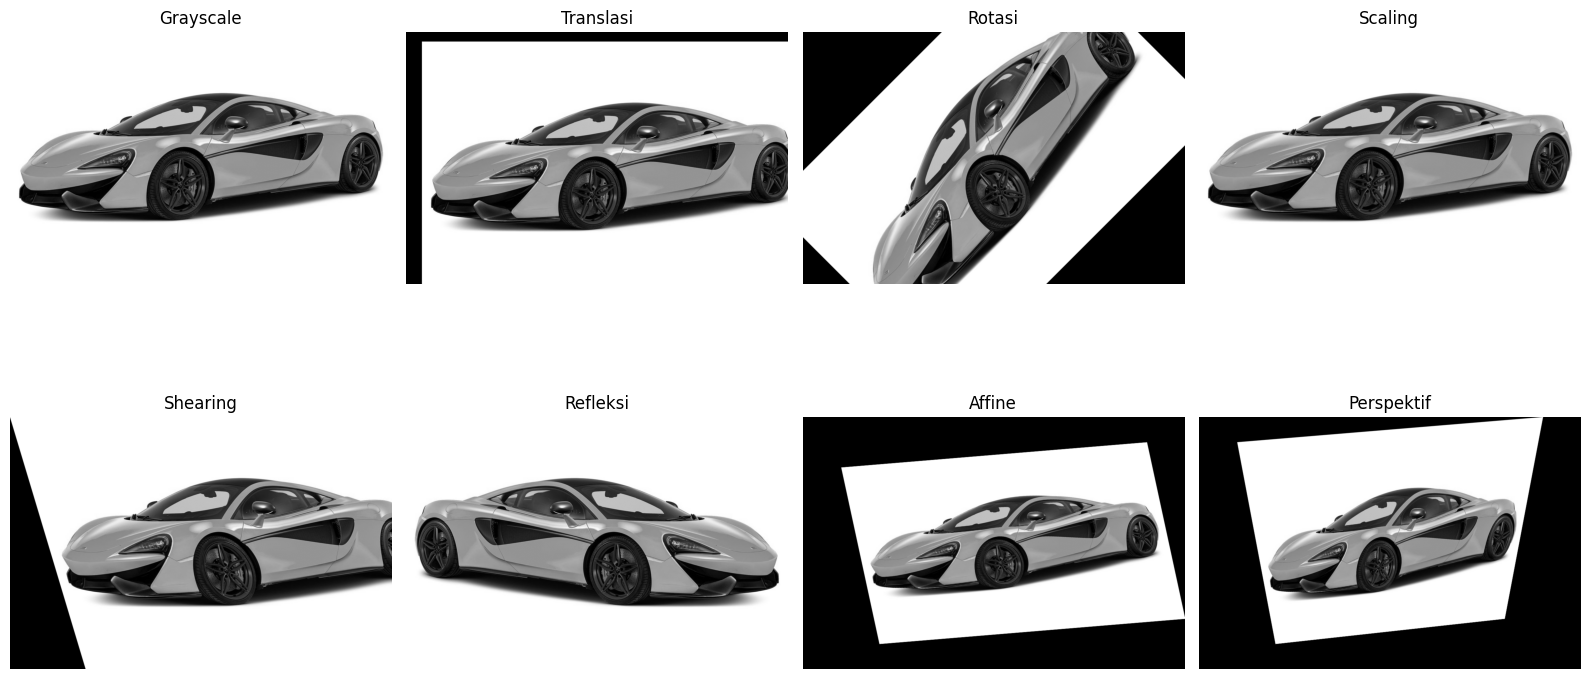

In [14]:
def tampilkan_hasil(img, hasil):

    judul = [
        "Grayscale",
        "Translasi",
        "Rotasi",
        "Scaling",
        "Shearing",
        "Refleksi",
        "Affine",
        "Perspektif"
    ]

    gambar = [
        img,
        hasil["translasi"],
        hasil["rotasi"],
        hasil["scaling"],
        hasil["shearing"],
        hasil["refleksi"],
        hasil["affine"],
        hasil["perspektif"]
    ]

    plt.figure(figsize=(16, 9))

    for i in range(8):

        plt.subplot(2, 4, i + 1)

        plt.imshow(gambar[i], cmap='gray')

        plt.title(judul[i], fontsize=12)

        plt.axis('off')

    plt.tight_layout()
    plt.show()


# Mengambil satu citra untuk visualisasi
img = baca_citra_grayscale(daftar_gambar[0])

hasil = proses_semua_transformasi(img)

tampilkan_hasil(img, hasil)

In [15]:
print("========== LAPORAN HASIL ==========")

total_output = 0

for jenis in jenis_transformasi:

    folder = os.path.join(folder_output, jenis)

    jumlah = len(
        glob.glob(os.path.join(folder, "*.jpg"))
    )

    total_output += jumlah

    print(f"{jenis.capitalize():15s}: {jumlah} citra")

print("-----------------------------------")
print("Total seluruh output:", total_output)
print("===================================")

========== LAPORAN HASIL ==========
Grayscale      : 20 citra
Translasi      : 20 citra
Rotasi         : 20 citra
Scaling        : 20 citra
Shearing       : 20 citra
Refleksi       : 20 citra
Affine         : 20 citra
Perspektif     : 20 citra
-----------------------------------
Total seluruh output: 160


In [17]:
import shutil

# Membuat file ZIP
shutil.make_archive(
    '/content/hasil_transformasi_geometris',
    'zip',
    folder_output
)

# Download hasil
files.download(
    '/content/hasil_transformasi_geometris.zip'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>